# Arrival-time distributions in a monitored 1D chain

Simulation code for the one-dimensional results of the paper
*"Arrival-time problem in the quantum information era – observation of the quantum Zeno crossover in monitored arrival-time dynamics"*.

**Protocol.** $k$ up-spins ($|1\rangle$) start on the first $k$ sites of an $L$-site chain. The system evolves under a brickwork circuit of XXZ gates
$$U_{ij}=\exp\!\left[-i\tau\left(X_iX_j+Y_iY_j+\Delta Z_iZ_j\right)\right],$$
applied in alternating even and odd layers. The detector qubit (last site) is measured every monitoring period $\Delta t$ with a mid-circuit measurement. The first-detection probability $P_a(t_n)$ is the probability that all earlier records are 'down' and the detector is 'up' at $t_n=n\Delta t$; its sum is the cumulative arrival probability $P_\Sigma(t_n)$.

**Noise handling.** Each monitoring time is a separate circuit. At its end all qubits are measured, and shots whose total particle number differs from $k$ are discarded (U(1) symmetry-based post-selection).

**Simulators.** `"aer"` = ideal AerSimulator, `"fake"` = AerSimulator with the noise model of an IBM fake backend. No IBM account is needed.

**Outputs.** (1) cumulative arrival probability, (2) local magnetization map, (3) error distribution (particle-number sectors before post-selection).

## 1. Imports

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import fake_provider      # only used for the noisy fake backends

## 2. Parameters — change these
All other cells use these values.

In [2]:
# ---------------- model ----------------
L        = 7          # number of qubits in the chain
K        = 1          # number of up-spins, prepared on sites 0, ..., K-1
DELTA    = 0.5        # anisotropy Delta of the XXZ gate
TAU      = 0.25       # gate parameter tau in exp[-i tau (XX + YY + Delta ZZ)]
LAYER_TIME = 0.5      # time per brickwork layer (one even + one odd layer = time 1)

# ---------------- monitoring ----------------
DT_LIST  = [1, 3, 5]  # monitoring periods Delta t (multiples of LAYER_TIME)
T        = 40         # final time: circuits for all t_n = n * Delta t <= T

# ---------------- simulation ----------------
MODES        = ["aer", "fake"]   # "aer" = ideal, "fake" = noisy fake backend (or only one)
FAKE_BACKEND = "FakeKingston"    # any backend in qiskit_ibm_runtime.fake_provider
SHOTS        = 2000              # shots per circuit (the paper used 20,000 on hardware)
SEED         = None              # None = independent random seeds, int = reproducible

# ---------------- plots ----------------
MAP_MODE, MAP_DT = "fake", 1     # run shown in the magnetization map and error distribution

# derived quantities (do not change)
N_QUBITS = L
DETECTOR = L - 1                 # monitored qubit
INIT_SITES = list(range(K))

## 3. Circuit
One circuit per monitoring time; the detector is measured after every monitoring period.

In [3]:
def brickwork_layers():
    """Nearest-neighbour bonds of the open chain, split into the even and odd layers."""
    even = [(i, i + 1) for i in range(0, L - 1, 2)]
    odd = [(i, i + 1) for i in range(1, L - 1, 2)]
    return [even, odd]


def apply_xxz_gate(qc, i, j):
    """exp[-i TAU (X_i X_j + Y_i Y_j + DELTA Z_i Z_j)].
    RXX(theta) = exp(-i theta/2 XX), so theta = 2*TAU. The three terms commute,
    so the product of the three rotations is exact."""
    theta = 2.0 * TAU
    qc.rxx(theta, i, j)
    qc.ryy(theta, i, j)
    qc.rzz(DELTA * theta, i, j)


def monitored_circuit(n_meas, layers_per_period):
    """Circuit ending at the n-th monitoring time t_n = n * Dt.

    Classical register 'c':
      bits 0 ... N_QUBITS-1         final measurement of all qubits at t_n
      bits N_QUBITS ... (+n_meas-2) mid-circuit records of the detector at t_1 ... t_{n-1}
    """
    qc = QuantumCircuit(QuantumRegister(N_QUBITS, "q"),
                        ClassicalRegister(N_QUBITS + n_meas - 1, "c"))
    for s in INIT_SITES:                       # up-spin = |1>
        qc.x(s)
    qc.barrier()

    layers = brickwork_layers()
    n_layers = n_meas * layers_per_period
    rec = 0
    for ell in range(1, n_layers + 1):
        for i, j in layers[(ell - 1) % len(layers)]:
            apply_xxz_gate(qc, i, j)
        # mid-circuit measurement of the detector after every monitoring period,
        # except at the final time (there all qubits are measured instead)
        if ell % layers_per_period == 0 and ell != n_layers:
            qc.measure(DETECTOR, N_QUBITS + rec)
            rec += 1
            qc.barrier()
    qc.barrier()
    qc.measure(range(N_QUBITS), range(N_QUBITS))
    return qc

Optional: draw a small example circuit (monitoring time $t_2$).

In [4]:
example = monitored_circuit(n_meas=2, layers_per_period=int(round(DT_LIST[0] / LAYER_TIME)))
print(example.draw(fold=-1))

     ┌───┐ ░ ┌───────────┐┌───────────┐                                                    ░ ┌───────────┐┌───────────┐                                                 ░ ┌─┐                  
q_0: ┤ X ├─░─┤0          ├┤0          ├─■──────────────────────────────────────────────────░─┤0          ├┤0          ├─■───────────────────────────────────────────────░─┤M├──────────────────
     └───┘ ░ │  Rxx(0.5) ││  Ryy(0.5) │ │ZZ(0.25) ┌───────────┐┌───────────┐               ░ │  Rxx(0.5) ││  Ryy(0.5) │ │ZZ(0.25) ┌───────────┐┌───────────┐            ░ └╥┘┌─┐               
q_1: ──────░─┤1          ├┤1          ├─■─────────┤0          ├┤0          ├─■─────────────░─┤1          ├┤1          ├─■─────────┤0          ├┤0          ├─■──────────░──╫─┤M├───────────────
           ░ ├───────────┤├───────────┤           │  Rxx(0.5) ││  Ryy(0.5) │ │ZZ(0.25)     ░ ├───────────┤├───────────┤           │  Rxx(0.5) ││  Ryy(0.5) │ │ZZ(0.25)  ░  ║ └╥┘┌─┐            
q_2: ──────░─┤0          ├┤0          ├─

## 4. Post-processing
Post-selection on the particle number, first-detection probability, occupation and error distribution.

In [5]:
def bits_of(bitstring, n_bits):
    """Qiskit bitstrings are little-endian: classical bit 0 is the right-most character.
    Returns an integer array b with b[i] = value of classical bit i."""
    s = bitstring.replace(" ", "")
    return np.array([int(s[-1 - i]) for i in range(n_bits)], dtype=np.int64)


def analyse_counts(counts, n_qubits, n_meas, k, detector):
    """Extract all quantities at one monitoring time t_n from the measured counts.

    Classical bits 0 ... n_qubits-1 hold the final measurement of all qubits, and the
    following n_meas-1 bits hold the mid-circuit records of the detector qubit.

    Returns a dict with
      P_a    : first-detection probability at t_n, Eq. (6) of the paper (post-selected)
      N_kept : number of shots kept by the U(1) post-selection
      occ    : up-spin probability of every qubit at t_n (post-selected, averaged over
               all measurement records)              -> local magnetization map
      weight : fraction of ALL shots with total particle number 0 ... n_qubits,
               before post-selection                  -> error distribution
    """
    n_bits = n_qubits + n_meas - 1
    weight = np.zeros(n_qubits + 1)
    occ = np.zeros(n_qubits)
    N_kept = 0
    n_first = 0
    for bitstring, c in counts.items():
        b = bits_of(bitstring, n_bits)
        final, records = b[:n_qubits], b[n_qubits:]
        w = int(final.sum())
        weight[w] += c
        if w != k:                    # U(1) post-selection: discard shots outside the
            continue                  # initial particle-number sector (hardware noise)
        N_kept += c
        occ += c * final
        # first detection at t_n: all earlier records 'down' and the detector 'up' now
        if records.sum() == 0 and final[detector] == 1:
            n_first += c
    total = sum(counts.values())
    return dict(P_a=n_first / N_kept if N_kept else np.nan,
                N_kept=N_kept,
                occ=occ / N_kept if N_kept else np.full(n_qubits, np.nan),
                weight=weight / total)

## 5. Simulation

In [6]:
def make_backend(mode, fake_name="FakeKingston"):
    """mode = 'aer'  : ideal, noiseless AerSimulator
       mode = 'fake' : AerSimulator with the noise model, native gates and coupling map
                       of an IBM fake backend (e.g. FakeKingston, FakeTorino, FakeFez)"""
    if mode == "aer":
        return AerSimulator(), None
    if mode == "fake":
        fake = getattr(fake_provider, fake_name)()
        return AerSimulator.from_backend(fake), \
            generate_preset_pass_manager(optimization_level=3, backend=fake)
    raise ValueError("mode must be 'aer' or 'fake'")


def run_arrival(Dt, mode="aer", seed=None):
    """Arrival-time statistics for one monitoring period Dt (uses the parameters above).

    One circuit is built for every monitoring time t_n = n*Dt <= T and run separately,
    exactly as on hardware. Returns a dict with
      t, P_a, P_sigma (cumulative), sigma (its standard deviation, Appendix B3),
      occ (n_times x n_qubits), weight (n_times x n_qubits+1), kept_fraction."""
    lpp = Dt / LAYER_TIME                                   # layers per monitoring period
    if abs(lpp - round(lpp)) > 1e-9 or lpp < 1:
        raise ValueError(f"Dt = {Dt} must be a positive multiple of LAYER_TIME = {LAYER_TIME}")
    lpp = int(round(lpp))
    n_list = list(range(1, int(np.floor(T / Dt + 1e-9)) + 1))

    circuits = [monitored_circuit(n, lpp) for n in n_list]
    sim, pm = make_backend(mode, FAKE_BACKEND)
    circuits_t = pm.run(circuits) if pm is not None else transpile(circuits, sim)

    t0 = time.time()
    # The circuits for t_1, t_2, ... share the same beginning, so they must be sampled with
    # DIFFERENT random seeds; otherwise their shot noise is correlated and adds up in the
    # cumulative P_Sigma. seed=None: independent seeds; integer: circuit i gets seed + i.
    if seed is None:
        result = sim.run(circuits_t, shots=SHOTS, max_parallel_experiments=0).result()
        counts = [result.get_counts(i) for i in range(len(circuits_t))]
    else:
        counts = [sim.run(c, shots=SHOTS, seed_simulator=seed + i).result().get_counts()
                  for i, c in enumerate(circuits_t)]
    print(f"{mode:>4s}, Dt = {Dt:g}: {len(circuits)} circuits in {time.time() - t0:.1f} s")

    out = [analyse_counts(counts[i], N_QUBITS, n, K, DETECTOR) for i, n in enumerate(n_list)]
    P_a = np.array([o["P_a"] for o in out])
    N_kept = np.array([o["N_kept"] for o in out])
    var_a = P_a * (1 - P_a) / np.maximum(N_kept, 1)         # Eq. (B1)
    return dict(t=Dt * np.array(n_list), P_a=P_a,
                P_sigma=np.cumsum(P_a),                     # Eq. (7)
                sigma=np.sqrt(np.cumsum(var_a)),            # Eq. (B2)
                occ=np.array([o["occ"] for o in out]),
                weight=np.array([o["weight"] for o in out]),
                kept_fraction=N_kept / SHOTS)

Run all monitoring periods for all simulators. Runtime grows with `SHOTS`, `T / Dt` and the number of qubits; the noisy fake backend is slower than the ideal simulator.

In [7]:
results = {}                       # results[(mode, Dt)] = dict returned by run_arrival
for mode in MODES:
    for Dt in DT_LIST:
        results[(mode, Dt)] = run_arrival(Dt, mode, seed=SEED)

 aer, Dt = 1: 40 circuits in 3.2 s
 aer, Dt = 3: 13 circuits in 1.2 s
 aer, Dt = 5: 8 circuits in 1.0 s
fake, Dt = 1: 40 circuits in 27.0 s
fake, Dt = 3: 13 circuits in 10.0 s
fake, Dt = 5: 8 circuits in 8.4 s


## 6. Cumulative arrival probability $P_\Sigma(t_n)$
Dashed: ideal simulator. Solid with markers: noisy fake backend after post-selection; the band is one standard deviation.

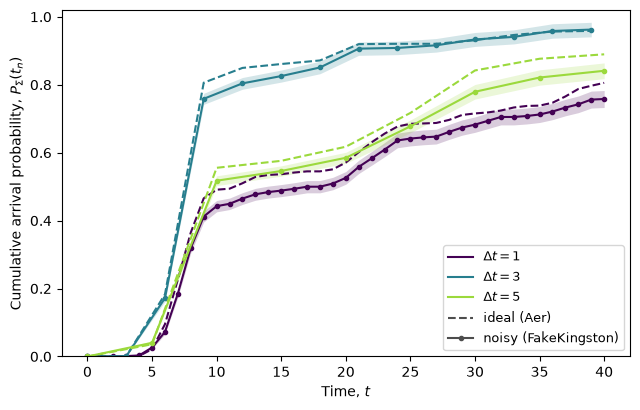

In [8]:
colors = plt.cm.viridis(np.linspace(0.0, 0.85, len(DT_LIST)))
style = {"aer": dict(ls="--", marker=None, label="ideal (Aer)"),
         "fake": dict(ls="-", marker="o", label=f"noisy ({FAKE_BACKEND})")}

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for c, Dt in zip(colors, DT_LIST):
    for mode in MODES:
        r = results[(mode, Dt)]
        t = np.concatenate(([0.0], r["t"]))
        P = np.concatenate(([0.0], r["P_sigma"]))
        ax.plot(t, P, color=c, ls=style[mode]["ls"], marker=style[mode]["marker"], ms=3)
        if mode == "fake":            # statistical uncertainty (one standard deviation)
            s = np.concatenate(([0.0], r["sigma"]))
            ax.fill_between(t, P - s, P + s, color=c, alpha=0.2, lw=0)
    ax.plot([], [], color=c, label=rf"$\Delta t={Dt:g}$")
for mode in MODES:                    # legend entries for the line styles
    ax.plot([], [], color="0.3", ls=style[mode]["ls"], marker=style[mode]["marker"],
            ms=3, label=style[mode]["label"])
ax.set_xlabel(r"Time, $t$")
ax.set_ylabel(r"Cumulative arrival probability, $P_\Sigma(t_n)$")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Local magnetization map
Up-spin probability of every qubit at the monitoring times, after post-selection and averaged over all measurement records.

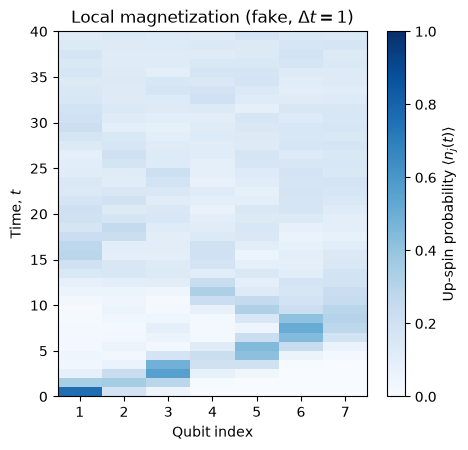

In [9]:
r = results[(MAP_MODE, MAP_DT)]

fig, ax = plt.subplots(figsize=(4.8, 4.6))
edges_t = np.concatenate(([0.0], r["t"]))
im = ax.pcolormesh(np.arange(1, N_QUBITS + 2) - 0.5, edges_t, r["occ"],
                   cmap="Blues", vmin=0, vmax=1)
ax.set_xlabel("Qubit index")
ax.set_ylabel(r"Time, $t$")
ax.set_xticks(range(1, N_QUBITS + 1))
ax.set_title(rf"Local magnetization ({MAP_MODE}, $\Delta t={MAP_DT:g}$)")
fig.colorbar(im, ax=ax, label=r"Up-spin probability $\langle n_j(t)\rangle$")
plt.tight_layout()
plt.show()

## 8. Error distribution
Fraction of all shots in each particle-number sector before post-selection. Only the sector with $k$ particles (between the dotted lines) is kept; the kept fraction is $N_i/N_{\rm shot}$.

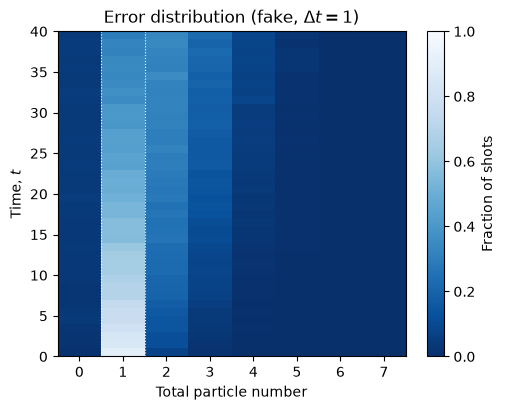

fraction kept by post-selection, N_i / N_shot: [0.9   0.848 0.833 0.796 0.77  0.764 0.743 0.693 0.692 0.674 0.648 0.646
 0.64  0.612 0.564 0.57  0.568 0.535 0.534 0.511 0.495 0.498 0.488 0.442
 0.449 0.43  0.434 0.43  0.395 0.403 0.402 0.354 0.37  0.35  0.335 0.346
 0.34  0.316 0.323 0.295]


In [10]:
mode_err, Dt_err = MAP_MODE, MAP_DT           # which run to show
r = results[(mode_err, Dt_err)]

fig, ax = plt.subplots(figsize=(5.2, 4.2))
edges_t = np.concatenate(([0.0], r["t"]))
im = ax.pcolormesh(np.arange(N_QUBITS + 2) - 0.5, edges_t, r["weight"],
                   cmap="Blues_r", vmin=0, vmax=1)
ax.axvline(K - 0.5, color="w", lw=0.8, ls=":")
ax.axvline(K + 0.5, color="w", lw=0.8, ls=":")
ax.set_xlabel("Total particle number")
ax.set_ylabel(r"Time, $t$")
ax.set_xticks(range(N_QUBITS + 1))
ax.set_title(rf"Error distribution ({mode_err}, $\Delta t={Dt_err:g}$)")
fig.colorbar(im, ax=ax, label="Fraction of shots")
plt.tight_layout()
plt.show()
print("fraction kept by post-selection, N_i / N_shot:", np.round(r["kept_fraction"], 3))